# Лабораторная работа № 4. Журналы ROS 2 без установленного ROS: MCAP, CDR, синхронизация и обнаружение событий

**Дисциплина:** «Методы обработки больших данных» · **Этапы пайплайна:** `Sense → Collect → Store → Process`
**Среда:** Google Colab · `mcap 1.5.0`, `mcap-ros2-support 0.5.7`, `rosbags 0.11.5` · **Максимум:** 10 баллов

## Поля для заполнения

| Поле | Значение |
|---|---|
| **Фамилия, имя, отчество** | Салимуллина Алия Дамировна|
| **Группа** | ИНДОР-221|
| **Вариант** |11 |
| **Дата выполнения** | 13.10.2026|

*(те же значения укажите в ячейке 1)*

## Критерии оценки

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | MCAP создан без ROS; разобраны схема, каналы и цена схемы записи | 2 |
| 2 | CDR декодирован; топики синхронизированы по времени с допуском | 2 |
| 3 | Признаки, обнаружение удара и метрики качества обнаружения | 2 |
| 4 | Edge-прореживание, Parquet, чтение rosbag2 через `rosbags` | 1 |
| 5 | Педагогическая часть: `TEACH CARD` и фрагмент занятия | 3 |

## Как работать

1. **Файл → Сохранить копию на Диске.**
2. В ячейке 1 укажите ФИО, группу и вариант. Параметры варианта считаются формулой — не
   правьте их вручную.
3. Выполняйте ячейки сверху вниз. Места `TODO` дописываете вы; до этого ячейка останавливается
   с `NotImplementedError`.
4. Поля **«Ваш ответ»** и пустые ячейки таблиц оцениваются так же, как код.
5. Все выводы — по **вашим** числам и графикам.

## Теоретический минимум

| Уровень | Что это | Пример |
|---|---|---|
| сообщение | объект определённого типа | `std_msgs/Float64`, `sensor_msgs/Imu` |
| топик | именованный канал сообщений одного типа | `/imu/ax`, `/imu/data` |
| сериализация | объект → байты (в ROS 2 обычно CDR) | 12 байт на `Float64` |
| хранилище | контейнер журнала | MCAP, SQLite3 |

Формулы: поток $R = f\cdot s$; норма $\lVert a\rVert = \sqrt{a_x^2+a_y^2+a_z^2}$; скользящий RMS;
$z = (x-\mu)/\sigma$; синхронизация по ближайшему соседу $|t_i - t_{j^*}| \le \varepsilon$;
прореживание $f_{out} = f_{in}/M$. Подробнее — в лекции «Большие данные робототехнических и
IoT-систем» и в `README_lab_04.md`.

---
# Часть 1. Запись MCAP без ROS (2 балла)

## Ячейка 1. Вариант и параметры (дана готовой, заполните три строки)

In [ ]:
!pip -q install "mcap==1.5.0" "mcap-ros2-support==0.5.7" "rosbags==0.11.5" pyarrow   # в Colab
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# =========== ЗАПОЛНИТЕ ===========
STUDENT_NAME  = "Салимуллина Алия Дамировна"   # <-- ваши ФИО
STUDENT_GROUP = "ИНДОР-221"                # <-- ваша группа
VARIANT       = 11                       # <-- ваш вариант
# =================================
assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта: группа (n−1)//5 — частота, джиттер, прореживание;
    позиция (n−1)%5 — параметры удара, шум, окно признаков, аудитория."""
    return {
        "freq_hz":      [25, 50, 100, 200, 400][(n - 1) // 5],
        "jitter_frac":  [0.10, 0.15, 0.20, 0.25, 0.30][(n - 1) // 5],   # доля периода
        "decimation":   [5, 5, 10, 10, 20][(n - 1) // 5],
        "shock_start":  [4.0, 8.0, 12.0, 6.0, 15.0][(n - 1) % 5],
        "shock_len":    [0.20, 0.30, 0.50, 0.10, 0.40][(n - 1) % 5],
        "shock_ax":     [2.0, 3.0, 1.5, 4.0, 2.5][(n - 1) % 5],
        "noise_std":    [0.02, 0.03, 0.05, 0.04, 0.06][(n - 1) % 5],
        "rms_window_s": [0.10, 0.20, 0.30, 0.20, 0.10][(n - 1) % 5],
        "audience":     ["5–7 класс", "8–9 класс", "10–11 класс",
                         "кружок робототехники", "СПО"][(n - 1) % 5],
        "duration_s":   20.0,
        "seed":         400 + n,
    }


CFG = variant_params(VARIANT)
WORK = Path("/content") if Path("/content").exists() else Path("lab04_work")
WORK.mkdir(exist_ok=True)

print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}, вариант {VARIANT}")
for key, value in CFG.items():
    print(f"  {key:<13}: {value}")
period_ms = 1000 / CFG["freq_hz"]
print(f"\nПериод опроса {period_ms:.1f} мс, отсчётов за прогон "
      f"{int(CFG['freq_hz'] * CFG['duration_s'])}, удар длится "
      f"{int(round(CFG['shock_len'] * CFG['freq_hz']))} отсчётов")



def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.9/144.9 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.0 MB/s eta 0:00:00
Студент : Салимуллина Алия Дамировна, группа ИНДОР-221, вариант 11
  freq_hz      : 100
  jitter_frac  : 0.2
  decimation   : 10
  shock_start  : 4.0
  shock_len    : 0.2
  shock_ax     : 2.0
  noise_std    : 0.02
  rms_window_s : 0.1
  audience     : 5–7 класс
  duration_s   : 20.0
  seed         : 411

Период опроса 10.0 мс, отсчётов за прогон 2000, удар длится 20 отсчётов


## Ячейка 2. Исходный сигнал IMU (дана готовой)

Моделирует драйвер датчика: колебания корпуса, гравитация по оси z, удар в горизонтальной
плоскости, шум. **У каждой оси свой джиттер меток времени** — как у независимых топиков ROS 2.
Изучите график: на какой оси виден удар, а на какой — нет?

Отсчётов: 2000, из них в ударе: 20
Джиттер меток времени: ±2.00 мс при периоде 10.0 мс


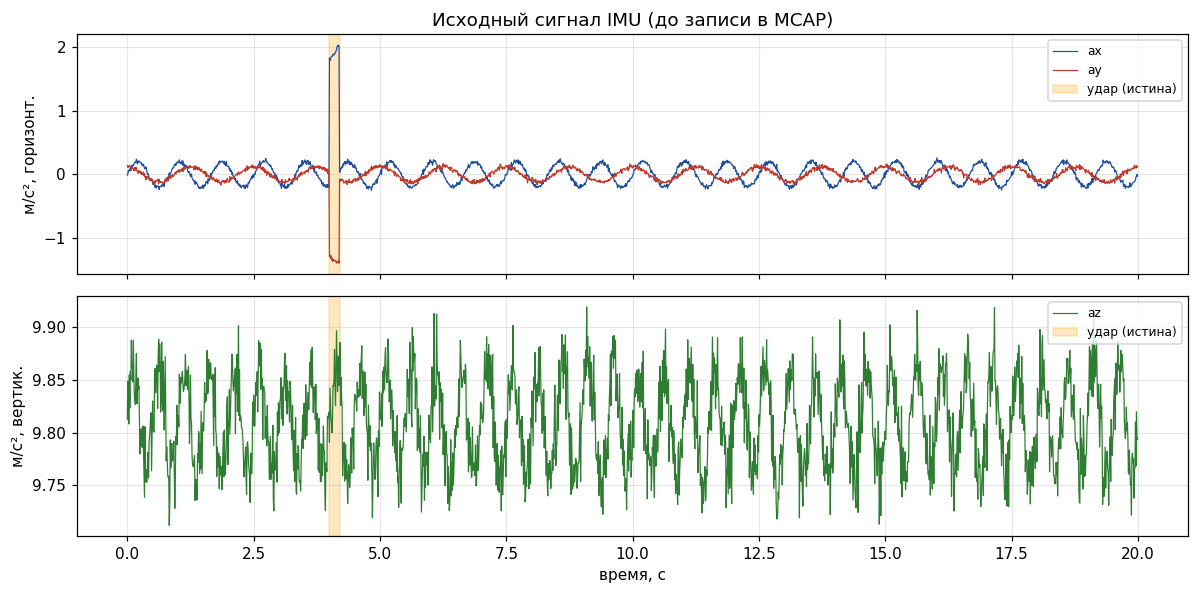

In [ ]:
rng = np.random.default_rng(CFG["seed"])
f, T = CFG["freq_hz"], CFG["duration_s"]
n = int(f * T)
t = np.arange(n) / f
T0_NS = 1_720_000_000_000_000_000

# «Истинный» сигнал IMU: медленные колебания корпуса + гравитация по оси z
ax = 0.20 * np.sin(2 * np.pi * 1.2 * t)
ay = 0.12 * np.cos(2 * np.pi * 0.8 * t)
az = 9.81 + 0.05 * np.sin(2 * np.pi * 2.0 * t)

# Удар: кратковременный толчок в горизонтальной плоскости
is_shock = (t >= CFG["shock_start"]) & (t < CFG["shock_start"] + CFG["shock_len"])
ax = ax + CFG["shock_ax"] * is_shock
ay = ay - (2 / 3) * CFG["shock_ax"] * is_shock

# Шум датчика
noisy = {name: sig + rng.normal(0, CFG["noise_std"], n)
         for name, sig in (("ax", ax), ("ay", ay), ("az", az))}

# Метки времени: у каждой оси свой джиттер (топики публикуются независимо)
jitter_ns = CFG["jitter_frac"] * 1e9 / f
stamps = {name: (T0_NS + (t * 1e9).astype(np.int64)
                 + rng.uniform(-jitter_ns, jitter_ns, n).astype(np.int64))
          for name in noisy}

truth = pd.DataFrame({"time_s": t, "is_shock": is_shock, **noisy})
print(f"Отсчётов: {n}, из них в ударе: {is_shock.sum()}")
print(f"Джиттер меток времени: ±{jitter_ns / 1e6:.2f} мс при периоде {1000 / f:.1f} мс")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for name, color in (("ax", "#1f4e9c"), ("ay", "#c0392b")):
    axes[0].plot(t, noisy[name], lw=0.8, color=color, label=name)
axes[1].plot(t, noisy["az"], lw=0.8, color="#2e7d32", label="az")
for a in axes:
    a.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"],
              color="orange", alpha=0.25, label="удар (истина)")
    a.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("м/с², горизонт.")
axes[1].set_ylabel("м/с², вертик.")
axes[1].set_xlabel("время, с")
axes[0].set_title("Исходный сигнал IMU (до записи в MCAP)")
plt.tight_layout()
plt.show()

**Ваш ответ.** На каких осях виден удар и почему вертикальное ускорение неподвижного робота
близко к 9,81 м/с², а не к нулю?

> Удар заметен на осях X и Y, особенно на X. По оси Z ускорение около 9,81 м/с², потому что робот стоит на опоре, которая не даёт ему упасть. Акселерометр измеряет действие этой опоры, поэтому даже у неподвижного робота показание не равно нулю.

## Ячейка 3. Две схемы записи

**TODO 3.** Напишите две функции записи MCAP через `mcap_ros2.writer.Writer` (ROS 2 не нужен):

* `write_float64(path, compression)` — три топика `/imu/ax`, `/imu/ay`, `/imu/az` с типом
  `std_msgs/Float64` (определение `"float64 data"`), у каждого сообщения своя метка времени
  `stamps[axis][i]`;
* `write_vector(path, compression)` — один топик `/imu/accel` с типом `lab_msgs/Accel3`
  (определение `"float64 x\nfloat64 y\nfloat64 z"`), метка времени — `stamps["ax"][i]`.

Запишите обе схемы без сжатия (`CompressionType.NONE`) и с `CompressionType.ZSTD`, сведите в
таблицу размеры файлов и байты на отсчёт, постройте столбчатую диаграмму с линией полезных
данных ($n \times 3 \times 8$ байт). Основной файл работы — `MCAP_FILE`, схема `write_float64`
со сжатием zstd.

Полезных данных: 2000 отсчётов × 3 оси × 8 байт = 48000 байт

           схема     сжатие  сообщений   байт  байт на отсчёт
3 топика Float64 без сжатия       6000 354878           177.4
3 топика Float64       zstd       6000 194934            97.5
  1 топик Accel3 без сжатия       2000 150706            75.4
  1 топик Accel3       zstd       2000  93987            47.0


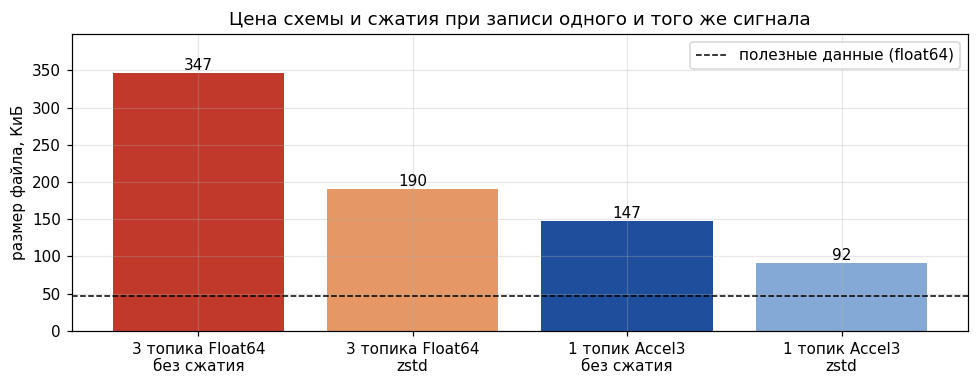

In [ ]:
from mcap_ros2.writer import Writer as McapWriter
from mcap.writer import CompressionType

MCAP_FILE = WORK / "robot_imu_ros2.mcap"
def write_float64(path: Path, compression=CompressionType.ZSTD) -> int:
    """Схема из исходной лабораторной: три топика std_msgs/Float64, по одному на ось."""
    with path.open("wb") as fh:
        writer = McapWriter(fh, compression=compression)
        schema = writer.register_msgdef("std_msgs/Float64", "float64 data")
        for i in range(n):
            for axis in ("ax", "ay", "az"):
                writer.write_message(topic=f"/imu/{axis}", schema=schema,
                                     message={"data": float(noisy[axis][i])},
                                     log_time=int(stamps[axis][i]),
                                     publish_time=int(stamps[axis][i]), sequence=i)
        writer.finish()
    return 3 * n


def write_vector(path: Path, compression=CompressionType.ZSTD) -> int:
    """Одно сообщение на отсчёт: три оси в одном типе lab_msgs/Accel3."""
    with path.open("wb") as fh:
        writer = McapWriter(fh, compression=compression)
        schema = writer.register_msgdef("lab_msgs/Accel3", "float64 x\nfloat64 y\nfloat64 z")
        for i in range(n):
            ts = int(stamps["ax"][i])
            writer.write_message(topic="/imu/accel", schema=schema,
                                 message={"x": float(noisy["ax"][i]), "y": float(noisy["ay"][i]),
                                          "z": float(noisy["az"][i])},
                                 log_time=ts, publish_time=ts, sequence=i)
        writer.finish()
    return n


MCAP_FILE = WORK / "robot_imu_ros2.mcap"
layouts = []
for label, func in (("3 топика Float64", write_float64), ("1 топик Accel3", write_vector)):
    for comp_name, comp in (("без сжатия", CompressionType.NONE), ("zstd", CompressionType.ZSTD)):
        path = WORK / f"layout_{len(layouts)}.mcap"
        messages = func(path, comp)
        layouts.append({"схема": label, "сжатие": comp_name, "сообщений": messages,
                        "байт": path.stat().st_size,
                        "байт на отсчёт": round(path.stat().st_size / n, 1)})
write_float64(MCAP_FILE)                                    # основной файл работы
layout_df = pd.DataFrame(layouts)
payload = n * 3 * 8
print(f"Полезных данных: {n} отсчётов × 3 оси × 8 байт = {payload} байт\n")
print(layout_df.to_string(index=False))

fig, axp = plt.subplots(figsize=(9, 3.6))
labels = [f"{r['схема']}\n{r['сжатие']}" for r in layouts]
colors = ["#c0392b", "#e59866", "#1f4e9c", "#85a9d6"]
bars = axp.bar(labels, layout_df["байт"] / 1024, color=colors)
axp.axhline(payload / 1024, color="black", ls="--", lw=1, label="полезные данные (float64)")
for bar, value in zip(bars, layout_df["байт"] / 1024):
    axp.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.0f}", ha="center", va="bottom")
axp.set_ylim(0, layout_df["байт"].max() / 1024 * 1.15)
axp.set_ylabel("размер файла, КиБ")
axp.set_title("Цена схемы и сжатия при записи одного и того же сигнала")
axp.legend()
plt.tight_layout()
plt.show()
# TODO 3: функции write_float64 и write_vector, таблица layout_df и диаграмма


**Ваш ответ.** Заполните по своим числам:

| Схема | Сжатие | Байт | Байт на отсчёт |
|---|---|---:|---:|
| 3 топика Float64 | нет |354878 | 177.4 |
| 3 топика Float64 | zstd | 194934| 97.5 |
| 1 топик Accel3 | нет |150706  | 75.4|
| 1 топик Accel3 | zstd |93987  | 47.0 |

Во сколько раз схема «три топика» без сжатия больше полезных данных и почему? Решает ли
сжатие эту проблему?

> *Схема с тремя топиками без сжатия занимает примерно в 7,4 раза больше места, чем полезные данные (354878 против 48000 байт). Это связано с дополнительной информацией, которая хранится для каждого сообщения. Сжатие уменьшает размер файла, но полностью проблему не решает, так как дополнительные данные всё равно сохраняются.*

## Ячейка 4. Что внутри файла

**TODO 4.** Прочитайте только сводку `make_reader(fh).get_summary()`: схемы (имя, кодировка),
каналы (топик, кодировка сообщений, число сообщений), общее число сообщений, интервал записи в
секундах, число чанков и тип сжатия.

In [ ]:
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

with MCAP_FILE.open("rb") as fh:
    summary = make_reader(fh).get_summary()

print("Схемы:")
for sch in summary.schemas.values():
    print(f"  id={sch.id}  {sch.name:<18} кодировка определения: {sch.encoding}")
print("Каналы:")
for ch in summary.channels.values():
    count = summary.statistics.channel_message_counts[ch.id]
    print(f"  id={ch.id}  {ch.topic:<8} сообщения: {ch.message_encoding}  количество: {count}")
stats = summary.statistics
print(f"\nВсего сообщений: {stats.message_count}")
print(f"Интервал записи: {(stats.message_end_time - stats.message_start_time) / 1e9:.3f} с")
print(f"Чанков: {len(summary.chunk_indexes)}, "
      f"сжатие: {sorted(set(ci.compression for ci in summary.chunk_indexes))}")

Схемы:
  id=1  std_msgs/Float64   кодировка определения: ros2msg
Каналы:
  id=1  /imu/ax  сообщения: cdr  количество: 2000
  id=2  /imu/ay  сообщения: cdr  количество: 2000
  id=3  /imu/az  сообщения: cdr  количество: 2000

Всего сообщений: 6000
Интервал записи: 19.993 с
Чанков: 1, сжатие: ['zstd']


---
# Часть 2. Декодирование и синхронизация (2 балла)

## Ячейка 5. CDR-декодирование

**TODO 5.** Прочитайте все сообщения через
`make_reader(fh, decoder_factories=[DecoderFactory()]).iter_decoded_messages()` и соберите
«длинную» таблицу `long` с колонками `topic`, `axis`, `log_time`, `value`, `cdr_bytes`
(`len(message.data)`). Выведите число сообщений и размер CDR-нагрузки.

In [ ]:
records = []
with MCAP_FILE.open("rb") as fh:
    reader = make_reader(fh, decoder_factories=[DecoderFactory()])
    for schema, channel, message, ros_msg in reader.iter_decoded_messages():
        records.append({"topic": channel.topic, "axis": channel.topic.split("/")[-1],
                        "log_time": message.log_time, "value": float(ros_msg.data),
                        "cdr_bytes": len(message.data)})
long = pd.DataFrame(records)
print(f"Декодировано сообщений: {len(long)}")
print(f"Размер CDR-полезной нагрузки одного сообщения: {long['cdr_bytes'].unique()} байт "
      f"(4 байта заголовка CDR + 8 байт float64)")
print(long.head(6).to_string(index=False))

Декодировано сообщений: 6000
Размер CDR-полезной нагрузки одного сообщения: [12] байт (4 байта заголовка CDR + 8 байт float64)
  topic axis            log_time     value  cdr_bytes
/imu/ay   ay 1719999999998129252  0.135778         12
/imu/az   az 1719999999999584056  9.812634         12
/imu/ax   ax 1720000000000379474 -0.012382         12
/imu/az   az 1720000000009894996  9.848788         12
/imu/ax   ax 1720000000010218393  0.007460         12
/imu/ay   ay 1720000000011908638  0.108218         12


## Ячейка 6. Синхронизация

**TODO 6.** Соберите строки «время — ax — ay — az» двумя способами:

1. по **точному** совпадению `log_time` (`pivot_table`) — посчитайте долю полных строк;
2. по **ближайшему соседу** через `pd.merge_asof(..., direction="nearest", tolerance=EPS_NS)`,
   где `EPS_NS` — половина периода опроса в наносекундах. Базовая ось — `ax`.

Для второго способа посчитайте рассогласование меток внутри строки (`sync_err_ms`) и постройте
его гистограмму с линией допуска. Результат — таблица `synced` без пропусков.

Точное совпадение: строк 6000, полных (все три оси) 0 — 0.0 % от 2000 отсчётов
merge_asof (eps = 5.0 мс): полных строк 2000 — 100.0 %
Ошибка синхронизации: медиана 1.76 мс, максимум 3.97 мс


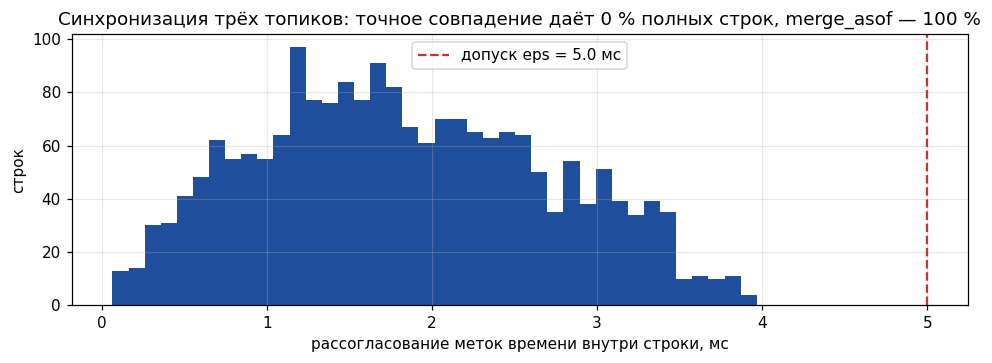

In [ ]:
# Способ из исходной работы: строки собираются по точному совпадению log_time
exact = long.pivot_table(index="log_time", columns="axis", values="value")
complete_exact = exact.dropna()
print(f"Точное совпадение: строк {len(exact)}, полных (все три оси) {len(complete_exact)} "
      f"— {100 * len(complete_exact) / n:.1f} % от {n} отсчётов")

# Правильный способ: ближайший сосед в пределах допуска eps (лекция, §9)
EPS_NS = int(0.5e9 / CFG["freq_hz"])                 # половина периода
base = long[long.axis == "ax"].sort_values("log_time")[["log_time", "value"]].rename(columns={"value": "ax"})
synced = base.copy()
for axis in ("ay", "az"):
    other = (long[long.axis == axis].sort_values("log_time")[["log_time", "value"]]
             .rename(columns={"value": axis, "log_time": f"t_{axis}"}))
    synced = pd.merge_asof(synced, other, left_on="log_time", right_on=f"t_{axis}",
                           direction="nearest", tolerance=EPS_NS)
synced["sync_err_ms"] = np.maximum((synced["log_time"] - synced["t_ay"]).abs(),
                                   (synced["log_time"] - synced["t_az"]).abs()) / 1e6
synced = synced.dropna().reset_index(drop=True)
print(f"merge_asof (eps = {EPS_NS / 1e6:.1f} мс): полных строк {len(synced)} "
      f"— {100 * len(synced) / n:.1f} %")
print(f"Ошибка синхронизации: медиана {synced['sync_err_ms'].median():.2f} мс, "
      f"максимум {synced['sync_err_ms'].max():.2f} мс")

fig, axs = plt.subplots(figsize=(9, 3.4))
axs.hist(synced["sync_err_ms"], bins=40, color="#1f4e9c")
axs.axvline(EPS_NS / 1e6, color="#c0392b", ls="--", label=f"допуск eps = {EPS_NS / 1e6:.1f} мс")
axs.set_xlabel("рассогласование меток времени внутри строки, мс")
axs.set_ylabel("строк")
axs.set_title(f"Синхронизация трёх топиков: точное совпадение даёт "
              f"{100 * len(complete_exact) / n:.0f} % полных строк, merge_asof — "
              f"{100 * len(synced) / n:.0f} %")
axs.legend()
plt.tight_layout()
plt.show()

**Ваш ответ.**

| Способ | Полных строк, % |
|---|---:|
| точное совпадение времени |0 |
| `merge_asof` с допуском ____ мс |100 |

Медиана и максимум рассогласования: 1,76 мс / 3.97 мс. Почему первый способ не работает на
ваших данных и что случится при допуске больше периода опроса?

> *Первый способ не работает, потому что датчики записывают данные с небольшими различиями во времени, поэтому их метки не совпадают. Метод `merge_asof` позволяет объединить близкие по времени измерения. Если допуск будет больше периода опроса, можно ошибочно объединить измерения, сделанные в разные моменты времени.*

---
# Часть 3. Признаки и обнаружение удара (2 балла)

## Ячейка 7. Норма или горизонтальная составляющая

**TODO 7.** По таблице `synced` постройте `imu` с колонками `time_s`, `accel_norm`,
`horiz` $=\sqrt{a_x^2+a_y^2}$ и `is_shock` (истинный интервал удара из `CFG`).

Напишите функцию `detect(feature, name)`:

1. отклонение от медианы базового участка (`time_s < shock_start − 1`);
2. скользящий RMS отклонения в окне `W = rms_window_s × freq_hz` отсчётов;
3. Z-score RMS относительно базового участка, тревога при $Z \ge 3$;
4. TP, FP, FN, precision, recall, задержка обнаружения (мс) и число FP **вне хвоста окна** —
   то есть дальше чем `W / freq_hz` секунд после конца удара.

Примените к обоим признакам, выведите таблицу и рост каждого признака во время удара.
Постройте три панели: признаки; Z-score с порогом; тревоги и истинный удар.

Окно RMS: 10 отсчётов (100 мс), порог |Z| ≥ 3

признак  пик Z  TP  FP  FP вне хвоста окна  FN  precision  recall  задержка, мс
   norm   33.0  21  14                   6   0      0.600     1.0           1.2
  horiz  112.7  21   8                   0   0      0.724     1.0           1.2

Рост нормы в ударе: 0.293 м/с², рост горизонтальной составляющей: 2.073 м/с²


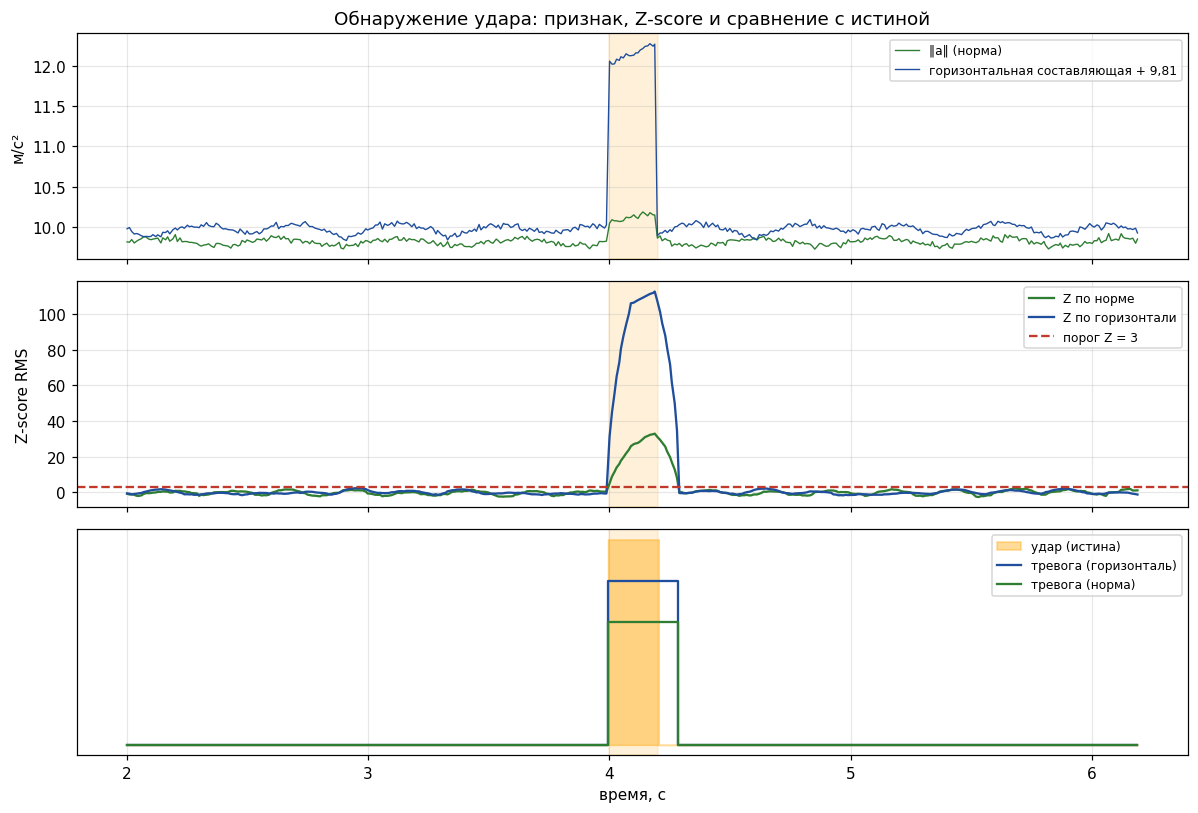

In [ ]:
imu = synced[["log_time", "ax", "ay", "az"]].copy()
imu["time_s"] = (imu["log_time"] - T0_NS) / 1e9
imu["accel_norm"] = np.sqrt(imu.ax ** 2 + imu.ay ** 2 + imu.az ** 2)
imu["horiz"] = np.sqrt(imu.ax ** 2 + imu.ay ** 2)
imu["is_shock"] = ((imu.time_s >= CFG["shock_start"])
                   & (imu.time_s < CFG["shock_start"] + CFG["shock_len"]))

W = max(int(round(CFG["rms_window_s"] * CFG["freq_hz"])), 2)
baseline = imu.time_s < CFG["shock_start"] - 1.0              # участок заведомо без удара


def detect(feature: pd.Series, name: str) -> dict:
    """Скользящий RMS отклонения от медианы + Z-score относительно базового участка."""
    dev = feature - feature[baseline].median()
    rms = np.sqrt((dev ** 2).rolling(W, min_periods=W).mean())
    z = (rms - rms[baseline].mean()) / rms[baseline].std()
    flag = z >= 3
    tp = int((flag & imu.is_shock).sum()); fp = int((flag & ~imu.is_shock).sum())
    fn = int((~flag & imu.is_shock).sum())
    first = imu.time_s[flag & imu.is_shock].min()
    # ложные тревоги сразу после удара — «хвост» окна RMS; дальние — настоящие ложные срабатывания
    tail = ((imu.time_s >= CFG["shock_start"] + CFG["shock_len"])
            & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + W / CFG["freq_hz"]))
    fp_far = int((flag & ~imu.is_shock & ~tail).sum())
    imu[f"rms_{name}"], imu[f"z_{name}"], imu[f"flag_{name}"] = rms, z, flag
    return {"признак": name, "пик Z": round(float(z.max()), 1),
            "TP": tp, "FP": fp, "FP вне хвоста окна": fp_far, "FN": fn,
            "precision": round(tp / max(tp + fp, 1), 3), "recall": round(tp / max(tp + fn, 1), 3),
            "задержка, мс": round((first - CFG["shock_start"]) * 1000, 1) if pd.notna(first) else None}


detection = pd.DataFrame([detect(imu.accel_norm, "norm"), detect(imu.horiz, "horiz")])
print(f"Окно RMS: {W} отсчётов ({W / CFG['freq_hz'] * 1000:.0f} мс), порог |Z| ≥ 3\n")
print(detection.to_string(index=False))
print(f"\nРост нормы в ударе: {imu.accel_norm[imu.is_shock].mean() - imu.accel_norm[~imu.is_shock].mean():.3f} м/с², "
      f"рост горизонтальной составляющей: {imu.horiz[imu.is_shock].mean() - imu.horiz[~imu.is_shock].mean():.3f} м/с²")

zoom = (imu.time_s > CFG["shock_start"] - 2) & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + 2)
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
axes[0].plot(imu.time_s[zoom], imu.accel_norm[zoom], color="#2e7d32", lw=0.9, label="‖a‖ (норма)")
axes[0].plot(imu.time_s[zoom], imu.horiz[zoom] + 9.81, color="#1f4e9c", lw=0.9,
             label="горизонтальная составляющая + 9,81")
axes[0].set_ylabel("м/с²")
axes[1].plot(imu.time_s[zoom], imu.z_norm[zoom], color="#2e7d32", label="Z по норме")
axes[1].plot(imu.time_s[zoom], imu.z_horiz[zoom], color="#1f4e9c", label="Z по горизонтали")
axes[1].axhline(3, color="#c0392b", ls="--", label="порог Z = 3")
axes[1].set_ylabel("Z-score RMS")
axes[2].fill_between(imu.time_s[zoom], 0, imu.is_shock[zoom].astype(int), color="orange", alpha=0.4,
                     step="mid", label="удар (истина)")
axes[2].step(imu.time_s[zoom], imu.flag_horiz[zoom].astype(int) * 0.8, color="#1f4e9c", where="mid",
             label="тревога (горизонталь)")
axes[2].step(imu.time_s[zoom], imu.flag_norm[zoom].astype(int) * 0.6, color="#2e7d32", where="mid",
             label="тревога (норма)")
axes[2].set_yticks([])
axes[2].set_xlabel("время, с")
for a in axes:
    a.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"], color="orange", alpha=0.15)
    a.legend(loc="upper right", fontsize=8)
axes[0].set_title("Обнаружение удара: признак, Z-score и сравнение с истиной")
plt.tight_layout()
plt.show()

**Ваш ответ.**

| Признак | Пик Z | Precision | Recall | Задержка, мс |
|---|---:|---:|---:|---:|
| норма | 33,0|0,600 |1,0 | 1,2|
| горизонтальная составляющая |112,7 |0,724 |1,0 |1,2 |

1. Почему удар почти не виден в норме ускорения? (Подсказка: прямоугольный треугольник.)
   > *Потому что основную часть общего ускорения составляет вертикальная составляющая около 9,81 м/с². Горизонтальный удар увеличивает норму всего на 0,293 м/с², хотя сама горизонтальная составляющая возрастает на 2,073 м/с².*
2. Какие ложные тревоги объясняются хвостом окна RMS, а какие — свойствами сигнала?
   > *После окончания удара RMS ещё некоторое время учитывает его значения, поэтому появляются ложные тревоги. У нормы было 14 ложных тревог, из них 8 связаны с хвостом окна, а 6 — с особенностями сигнала. У горизонтальной составляющей все 8 ложных тревог связаны с хвостом окна.)*

---
# Часть 4. Edge, хранение и реальные журналы (1 балл)

## Ячейка 8. Прореживание

**TODO 8.** Уменьшите частоту в `M = CFG["decimation"]` раз двумя способами: каждый $M$-й отсчёт
и сглаживание скользящим средним длиной $M$ перед отбором. Для исходного и двух прореженных
потоков посчитайте число отсчётов в ударе, максимум горизонтальной составляющей и максимум Z в
ударе; посчитайте $K_{edge}$ и постройте график окрестности удара.

Прореживание в 10 раз: 100 Гц → 10 Гц, поток 2400 → 240 байт/с (K_edge = 10)
                    поток  отсчётов в ударе  макс. горизонт. в ударе  макс. Z в ударе
          исходный 100 Гц                21                    2.464             42.7
       каждый 10-й отсчёт                 3                    2.322             39.1
сглаживание + каждый 10-й                 3                    2.337             47.4


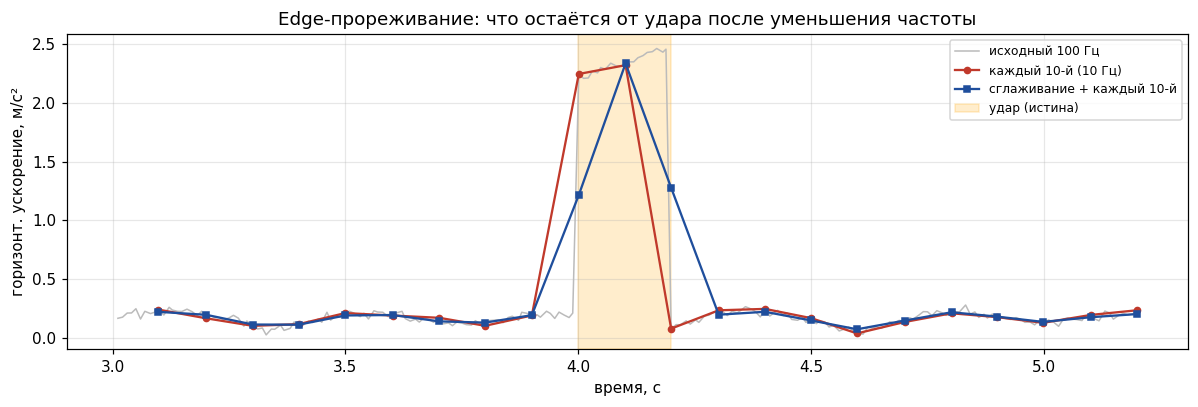

In [ ]:
M = CFG["decimation"]
f_out = CFG["freq_hz"] / M

naive = imu.iloc[::M].copy()                                       # просто каждый M-й отсчёт
smooth = imu[["time_s", "horiz", "is_shock"]].copy()
smooth["horiz"] = smooth["horiz"].rolling(M, center=True, min_periods=1).mean()   # НЧ-фильтр
filtered = smooth.iloc[::M].copy()

raw_rate = CFG["freq_hz"] * 3 * 8
out_rate = f_out * 3 * 8
print(f"Прореживание в {M} раз: {CFG['freq_hz']} Гц → {f_out:g} Гц, "
      f"поток {raw_rate} → {out_rate:g} байт/с (K_edge = {raw_rate / out_rate:g})")


def shock_seen(df: pd.DataFrame) -> dict:
    base = df[df.time_s < CFG["shock_start"] - 1.0]["horiz"]
    z = (df["horiz"] - base.mean()) / base.std()
    in_shock = df[df.is_shock]
    return {"отсчётов в ударе": len(in_shock),
            "макс. горизонт. в ударе": round(float(in_shock["horiz"].max()), 3) if len(in_shock) else None,
            "макс. Z в ударе": round(float(z[df.is_shock].max()), 1) if len(in_shock) else None}


decim = pd.DataFrame([{"поток": f"исходный {CFG['freq_hz']} Гц", **shock_seen(imu)},
                      {"поток": f"каждый {M}-й отсчёт", **shock_seen(naive)},
                      {"поток": f"сглаживание + каждый {M}-й", **shock_seen(filtered)}])
print(decim.to_string(index=False))

zoom = (imu.time_s > CFG["shock_start"] - 1) & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)
fig, axd = plt.subplots(figsize=(11, 3.8))
axd.plot(imu.time_s[zoom], imu.horiz[zoom], color="#bbbbbb", lw=1, label=f"исходный {CFG['freq_hz']} Гц")
zn = naive[(naive.time_s > CFG["shock_start"] - 1) & (naive.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)]
zf = filtered[(filtered.time_s > CFG["shock_start"] - 1) & (filtered.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)]
axd.plot(zn.time_s, zn.horiz, "o-", color="#c0392b", ms=4, label=f"каждый {M}-й ({f_out:g} Гц)")
axd.plot(zf.time_s, zf.horiz, "s-", color="#1f4e9c", ms=4, label=f"сглаживание + каждый {M}-й")
axd.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"], color="orange", alpha=0.2,
            label="удар (истина)")
axd.set_xlabel("время, с")
axd.set_ylabel("горизонт. ускорение, м/с²")
axd.set_title("Edge-прореживание: что остаётся от удара после уменьшения частоты")
axd.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Ячейка 9. Parquet и поток данных

**TODO 9.** Сохраните `imu` в Parquet и CSV, прочитайте Parquet обратно и проверьте совпадение.
Сравните размеры MCAP, CSV и Parquet; оцените поток записи MCAP в байтах в секунду и объём за
сутки.

               формат   байт                 что хранит  байт на отсчёт
MCAP (3 топика, zstd) 194934 журнал: схема, каналы, CDR            97.5
                  CSV 269319           текст, без типов           134.7
              Parquet 133499 колонки с типами и сжатием            66.7

R полезных данных: 2400 байт/с; R записи MCAP: 9747 байт/с
За сутки работы одного робота: 803 МиБ MCAP


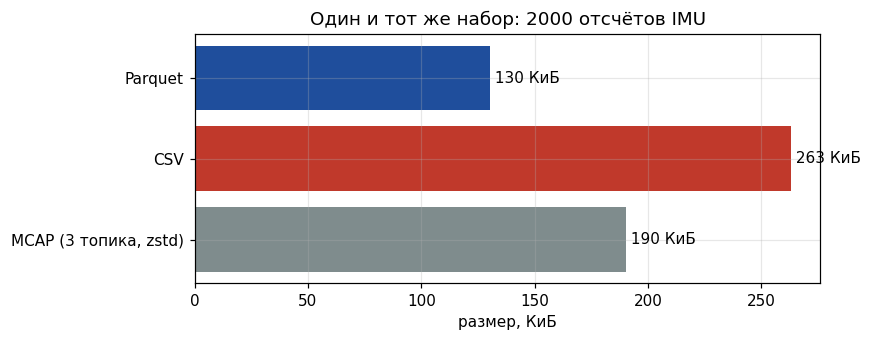

In [ ]:
PARQUET = WORK / "robot_imu.parquet"
CSV = WORK / "robot_imu.csv"
export = imu[["log_time", "time_s", "ax", "ay", "az", "accel_norm", "horiz", "is_shock"]]
export.to_parquet(PARQUET, index=False)
export.to_csv(CSV, index=False)

back = pd.read_parquet(PARQUET)
assert back.shape == export.shape and np.allclose(back.ax, export.ax)

sizes = pd.DataFrame([
    {"формат": "MCAP (3 топика, zstd)", "байт": MCAP_FILE.stat().st_size, "что хранит": "журнал: схема, каналы, CDR"},
    {"формат": "CSV", "байт": CSV.stat().st_size, "что хранит": "текст, без типов"},
    {"формат": "Parquet", "байт": PARQUET.stat().st_size, "что хранит": "колонки с типами и сжатием"},
])
sizes["байт на отсчёт"] = (sizes["байт"] / len(export)).round(1)
print(sizes.to_string(index=False))

# Оценка потока данных по формуле лекции R = f · s
rate_payload = CFG["freq_hz"] * 3 * 8
rate_mcap = MCAP_FILE.stat().st_size / CFG["duration_s"]
print(f"\nR полезных данных: {rate_payload} байт/с; R записи MCAP: {rate_mcap:.0f} байт/с")
print(f"За сутки работы одного робота: {rate_mcap * 86400 / 1024 ** 2:.0f} МиБ MCAP")

fig, axz = plt.subplots(figsize=(8, 3.2))
axz.barh(sizes["формат"], sizes["байт"] / 1024, color=["#7f8c8d", "#c0392b", "#1f4e9c"])
for y, value in enumerate(sizes["байт"] / 1024):
    axz.text(value, y, f" {value:.0f} КиБ", va="center")
axz.set_xlabel("размер, КиБ")
axz.set_title(f"Один и тот же набор: {len(export)} отсчётов IMU")
plt.tight_layout()
plt.show()

## Ячейка 10. `sensor_msgs/Imu` через `rosbags` (дана готовой)

Записывает настоящий каталог rosbag2 со стандартным типом ROS 2 и читает его тем же кодом,
что и журнал реального робота. Сравните размер CDR-нагрузки с вашими 12 байтами.

In [ ]:
import shutil
from rosbags.rosbag2 import Writer as BagWriter, StoragePlugin
from rosbags.typesys import Stores, get_typestore
from rosbags.highlevel import AnyReader

typestore = get_typestore(Stores.ROS2_HUMBLE)
Imu = typestore.types["sensor_msgs/msg/Imu"]
Header = typestore.types["std_msgs/msg/Header"]
Stamp = typestore.types["builtin_interfaces/msg/Time"]
Quat = typestore.types["geometry_msgs/msg/Quaternion"]
Vec3 = typestore.types["geometry_msgs/msg/Vector3"]

BAG = WORK / "imu_rosbag2"
shutil.rmtree(BAG, ignore_errors=True)
with BagWriter(BAG, version=9, storage_plugin=StoragePlugin.MCAP) as bag:
    conn = bag.add_connection("/imu/data", Imu.__msgtype__, typestore=typestore)
    for row in imu.itertuples():
        ns = int(row.log_time)
        msg = Imu(header=Header(stamp=Stamp(sec=ns // 10 ** 9, nanosec=ns % 10 ** 9), frame_id="imu_link"),
                  orientation=Quat(x=0.0, y=0.0, z=0.0, w=1.0), orientation_covariance=np.zeros(9),
                  angular_velocity=Vec3(x=0.0, y=0.0, z=0.0), angular_velocity_covariance=np.zeros(9),
                  linear_acceleration=Vec3(x=row.ax, y=row.ay, z=row.az),
                  linear_acceleration_covariance=np.zeros(9))
        bag.write(conn, ns, typestore.serialize_cdr(msg, Imu.__msgtype__))

rows, payload_sizes = [], set()
with AnyReader([BAG], default_typestore=typestore) as reader:
    for connection, stamp, raw in reader.messages():
        m = reader.deserialize(raw, connection.msgtype)
        payload_sizes.add(len(raw))
        rows.append((stamp, m.linear_acceleration.x, m.linear_acceleration.y, m.linear_acceleration.z))
from_bag = pd.DataFrame(rows, columns=["log_time", "ax", "ay", "az"])

print("Файлы rosbag2:", sorted(p.name for p in BAG.iterdir()))
print(f"Тип сообщения: {connection.msgtype}, топик {connection.topic}, сообщений {len(from_bag)}")
print(f"CDR-нагрузка одного sensor_msgs/Imu: {payload_sizes} байт против 3 × 12 = 36 байт у трёх Float64")
print(f"Совпадение с исходной таблицей: {np.allclose(from_bag[['ax', 'ay', 'az']].values, imu[['ax', 'ay', 'az']].values)}")

Файлы rosbag2: ['imu_rosbag2.mcap', 'metadata.yaml']
Тип сообщения: sensor_msgs/msg/Imu, топик /imu/data, сообщений 2000
CDR-нагрузка одного sensor_msgs/Imu: {324} байт против 3 × 12 = 36 байт у трёх Float64
Совпадение с исходной таблицей: True


**Ваш ответ (часть 4).**

| Показатель | Значение |
|---|---|
| отсчётов в ударе: исходный / каждый M-й / со сглаживанием | 21 / 3 / 3|
| $K_{edge}$ |10 |
| размер MCAP / CSV / Parquet, байт | 194934 / 269319 / 133499 |
| поток записи MCAP, байт/с; объём за сутки |9747 байт/с; 803 МиБ

При каком условии прореживание теряет удар целиком? Что изменится в коде, если подставить
журнал настоящего робота?

> Прореживание может полностью пропустить удар, если он слишком короткий и не попал в сохранённые измерения. В моём варианте осталось 3 отсчёта из 21, поэтому удар сохранился. Для работы с настоящим роботом нужно изменить путь к файлу и название топика, а при другом формате данных — способ их обработки.

---
# Часть 5. Педагогическая часть (3 балла)

Три утверждения, которые можно объяснить школьнику без слов «MCAP» и «CDR»:

1. **Число без метки времени — не измерение**: чтобы сравнить показания разных датчиков,
   нужно договориться, какие моменты считать «одновременными».
2. **Удар может спрятаться в норме**: выбор показателя важнее выбора порога.
3. **Экономить данные можно, но не вслепую**: прореживание может потерять короткое событие.

## 5.1. `TEACH CARD` (1,5 балла)

Аудитория задана вашим вариантом (`CFG["audience"]`), числа — из **вашего** прогона.

| Поле | Содержание |
|---|---|
| **Название учебного проекта** |«Как не пропустить короткий толчок робота» |
| **Целевая аудитория** | 5–7 класс |
| **Исследовательский вопрос** | Как частота измерений влияет на обнаружение короткого толчка и объём сохраняемых данных?|
| **Источник данных** |Подготовленная таблица показаний акселерометра по трём осям из ячейки 2; результаты прореживания из ячейки 8. В школе можно заменить её показаниями датчика смартфона|
| **Инженерная концепция, сохраняемая без упрощения** | Чем реже записываются измерения, тем меньше данных нужно хранить, но тем выше риск не заметить короткое событие. Проверка зависит от частоты измерений и длительности толчка|
| **Что упрощается относительно университетской лабораторной** |Вместо ROS, MCAP и программирования используются таблица и график. Ученики сравнивают исходный ряд измерений и каждый десятый отсчёт; принцип потери короткого события сохраняется |
| **Алгоритм действий обучающегося (4–6 шагов)** | 1. Получить таблицу показаний акселерометра. 2. Отметить момент толчка на графике. 3. Оставить каждое десятое измерение. 4. Сравнить графики до и после сокращения данных. 5. Подсчитать, сколько измерений осталось в момент толчка. 6. Объяснить, в какой ситуации толчок можно пропустить|
| **Измеримый результат / метрика** | Количество измерений во время толчка до и после сокращения данных, доля сохранившихся измерений и изменение максимального значения ускорения. Результаты определяются по таблице и графикам (ячейка 8)|
| **Критерий успешного выполнения** | Ученик правильно подсчитал количество измерений во время толчка до и после прореживания и объяснил, почему при более редкой записи можно пропустить короткий толчок|
| **Вариант усложнения для НТО / хакатона** |Создать программу, которая автоматически уменьшает частоту записи данных при спокойном движении и увеличивает её при резких изменениях показаний датчика, чтобы не пропустить короткий толчок |
| **Риски и ограничения** | В работе используется смоделированный толчок. В реальности датчики могут давать неточные показания, а сила и длительность толчков заранее неизвестны. Поэтому при сохранении каждого десятого измерения короткий толчок можно случайно пропустить|

## 5.2. Фрагмент занятия на 15–20 минут (1,5 балла)

| Пункт | Ваш ответ |
|---|---|
| Вывод (1, 2 или 3) | 3. **Экономить данные можно, но не вслепую**: прореживание может потерять короткое событие|
| Класс и формат |5–7 класс, практическая работа в парах с таблицей и графиками. |
| Время | 20 минут|
| Материалы | Таблица с показаниями акселерометра, графики ускорения, карандаши и листы для записи результатов|
| Числа вашего прогона и как они используются (не менее двух) |В эксперименте до прореживания было 21 измерение во время толчка, а после сохранения каждого 10-го измерения осталось 3. Ученики сравнивают эти результаты и выясняют, почему при сокращении данных можно пропустить короткий толчок|

**Прогноз учеников до проверки (что они предполагают и как записывают):**

Ученики предполагают, сохранится ли толчок, если записывать только каждое 10-е измерение. Свои предположения записывают на листе, а после выполнения задания сравнивают их с результатами.

**Ход фрагмента (3–5 шагов, кто что делает):**

1.  Подготовка (3 минуты).  Учитель показывает исходный график с толчком и предлагает ученикам предположить, сохранится ли он после сокращения количества измерений. Ученики записывают свой прогноз.
2. Работа с данными (5 минут). После записи прогноза ученики оставляют в таблице каждое 10-е измерение, а остальные вычёркивают.
3. Сравнение (5 минут). Ученики подсчитывают, сколько измерений толчка сохранилось, и сравнивают графики до и после прореживания.
4. Обсуждение (4 минуты). Ученики сравнивают результаты с данными эксперимента (21 и 3 измерения) и объясняют, почему сокращение данных может привести к потере информации.
5. Подведение итогов (3 минуты). Каждая пара формулирует вывод о преимуществах и недостатках сокращения количества измерений.

**Ключевой вопрос:** «Почему при сокращении количества измерений можно не заметить короткий толчок, даже если он действительно произошёл?»

**Проверка понимания (как узнаете, что вывод усвоен; какое заблуждение ловится):**
Ученикам предлагается ситуация: датчик измеряет ускорение каждые 10 мс, но сохраняется только каждое 10-е измерение. Они должны определить, можно ли пропустить толчок длительностью 20 мс, и объяснить свой ответ.
Ожидаемый ответ: толчок можно пропустить, потому что данные сохраняются только каждые 100 мс.
Задание проверяет понимание того, что при сокращении количества измерений часть важных событий может быть потеряна. Оно помогает выявить ошибочное мнение, что уменьшение объёма данных никак не влияет на их полноту.

**Критерии.** 1,5 балла — `TEACH CARD` заполнен полностью, аудитория соответствует варианту,
инженерная концепция не искажена. 1,5 балла — фрагмент содержит действия учеников, прогноз до
проверки, числа своего прогона, ключевой вопрос и проверку понимания. Не засчитывается
пересказ лекции, чужие числа и объяснение формата MCAP школьникам без связи с измерением.

---
## Самопроверка

In [ ]:
ANSWERS = {
    "size_float64_none": 354878,    # байт: 3 топика Float64 без сжатия
    "size_accel3_none": 150706,     # байт: 1 топик Accel3 без сжатия
    "exact_complete_pct": 0.0,   # % полных строк при точном совпадении времени
    "asof_complete_pct": 100.0,    # % полных строк при merge_asof
    "peak_z_norm":33.0,          # пик Z по норме
    "peak_z_horiz": 112.7,         # пик Z по горизонтальной составляющей
    "shock_samples_decimated": 3,  # отсчётов удара после простого прореживания
}

def has(name):
    return name in globals()

checks = {
    "Заполнены ФИО и группа":         STUDENT_NAME != "Иванов Иван Иванович",
    "Вариант 1..25":                  1 <= VARIANT <= 25,
    "MCAP создан":                    MCAP_FILE.exists(),
    "CDR декодирован":                has("long") and len(long) == 3 * n,
    "Синхронизация выполнена":        has("synced") and len(synced) >= 0.90 * n,
    "Признаки и обнаружение":         has("detection"),
    "Прореживание исследовано":       has("decim"),
    "rosbag2 прочитан":               has("from_bag") and len(from_bag) > 0,
    "ANSWERS заполнен":               all(v is not None for v in ANSWERS.values()),
    "Горизонталь сильнее нормы":      (ANSWERS["peak_z_horiz"] or 0) > (ANSWERS["peak_z_norm"] or 0),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print(f"\nВыполнено: {sum(checks.values())} из {len(checks)}")
print("Педагогическая часть (3 балла) проверяется преподавателем вручную.")

OK   Заполнены ФИО и группа
OK   Вариант 1..25
OK   MCAP создан
OK   CDR декодирован
OK   Синхронизация выполнена
OK   Признаки и обнаружение
OK   Прореживание исследовано
OK   rosbag2 прочитан
OK   ANSWERS заполнен
OK   Горизонталь сильнее нормы

Выполнено: 10 из 10
Педагогическая часть (3 балла) проверяется преподавателем вручную.


## Перед отправкой

- [ ] заполнены ФИО, группа, вариант и дата; параметры варианта не правились;
- [ ] выполнены все ячейки, графики и выводы сохранены;
- [ ] заполнены все поля «Ваш ответ» и словарь `ANSWERS`;
- [ ] `TEACH CARD` заполнен полностью, аудитория соответствует варианту;
- [ ] фрагмент занятия содержит прогноз учеников, действия, числа вашего прогона, ключевой
      вопрос и проверку понимания;
- [ ] самопроверка показывает «Выполнено: 10 из 10».